# Data visualization : Matplotlib and Seaborn
    1. anatomy            ---> Figure , Axes , the object-oriented API
    2. a house style      ---> one function that makes every chart consistent
    3. choose the form    ---> line , bar , histogram , scatter , box : which question does each answer ?
    4. layout             ---> subplots , shared axes , small multiples
    5. telling the story  ---> annotations , reference lines , direct labels , tick formats , log scale
    6. honest charts      ---> no dual axis , bars start at zero
    7. color for data     ---> categorical , sequential , diverging ; imshow and heatmaps
    8. Seaborn            ---> long data -> statistical plots , hue , facets
    9. saving figures     ---> png / svg , dpi , bbox_inches
   10. Persian text       ---> right-to-left labels
   11. applications       ---> EDA , bias-variance , decision boundaries , ROC / PR , time series ,
                               PCA map , gradient descent paths , model coefficients

In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
print("matplotlib", matplotlib.__version__, "| seaborn", sns.__version__)
# in Jupyter : charts appear under the cell automatically (or after plt.show())

matplotlib 3.11.2 | seaborn 0.13.2


## 1. Anatomy : a Figure contains one or more Axes
    Figure ---> the whole canvas (size , background , saving)
    Axes   ---> ONE plot : data , x-axis , y-axis , title , legend
    always prefer the object-oriented style :  fig, ax = plt.subplots()  then  ax.plot(...)

Figure | Axes | axes in figure: 1


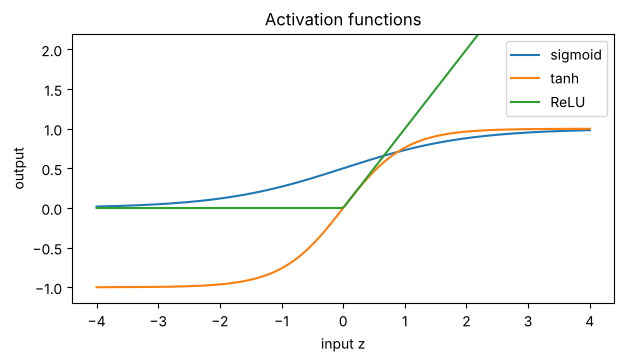

In [2]:
x = np.linspace(-4, 4, 200)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(x, 1 / (1 + np.exp(-x)), label="sigmoid")
ax.plot(x, np.tanh(x), label="tanh")
ax.plot(x, np.maximum(x, 0), label="ReLU")
ax.set_title("Activation functions")
ax.set_xlabel("input z")
ax.set_ylabel("output")
ax.set_ylim(-1.2, 2.2)
ax.legend()
plt.show()
print(type(fig).__name__, "|", type(ax).__name__, "| axes in figure:", len(fig.axes))

## 2. A house style : define it ONCE , use it everywhere
    thin marks , hairline solid grid , no top / right spines , quiet axis text ,
    a FIXED order of categorical colours (tested for colour-blind readers)

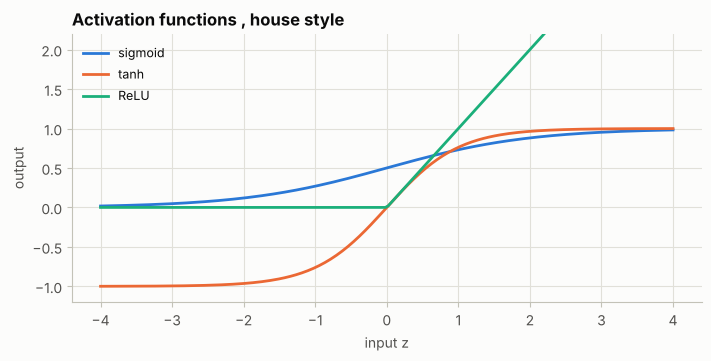

In [3]:
from cycler import cycler

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE, NEUTRAL = "#e1e0d9", "#c3c2b7", "#fcfcfb", "#f0efec"
BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]

def use_course_style():
    plt.rcParams.update({
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
        "axes.prop_cycle": cycler(color=SERIES),
        "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
        "axes.axisbelow": True,
        "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
        "axes.labelcolor": INK2, "axes.labelsize": 10,
        "text.color": INK,
        "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
        "lines.linewidth": 2, "lines.markersize": 6,
        "legend.frameon": False, "legend.fontsize": 9,
        "figure.dpi": 100, "figure.constrained_layout.use": True,
        "date.converter": "concise",                       # short , non-overlapping date ticks
    })
    sns.set_palette(SERIES)

use_course_style()

fig, ax = plt.subplots(figsize=(7, 3.5))
for name, f in [("sigmoid", lambda z: 1 / (1 + np.exp(-z))), ("tanh", np.tanh), ("ReLU", lambda z: np.maximum(z, 0))]:
    ax.plot(x, f(x), label=name)
ax.set(title="Activation functions , house style", xlabel="input z", ylabel="output", ylim=(-1.2, 2.2))
ax.legend(loc="upper left")
plt.show()

## 3. Choose the form by the QUESTION
| question | form |
|---|---|
| how does it change over time ? | line |
| how do categories compare ? | bar (sorted , starting at zero) |
| what does the distribution look like ? | histogram / KDE / box |
| how do two numbers relate ? | scatter |
| is it ONE number ? | just write the number |

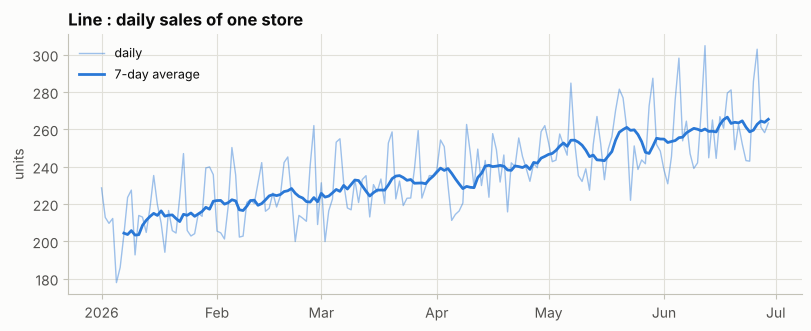

In [4]:
rng = np.random.default_rng(42)
days = pd.date_range("2026-01-01", periods=180, freq="D")
sales = 200 + np.linspace(0, 60, 180) + 25 * days.dayofweek.isin([3, 4]) + rng.normal(0, 12, 180)

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(days, sales, linewidth=1, color=SERIES[0], alpha=0.45, label="daily")
ax.plot(days, pd.Series(sales, index=days).rolling(7).mean(), color=SERIES[0], label="7-day average")
ax.set(title="Line : daily sales of one store", ylabel="units")
ax.legend(loc="upper left")
plt.show()

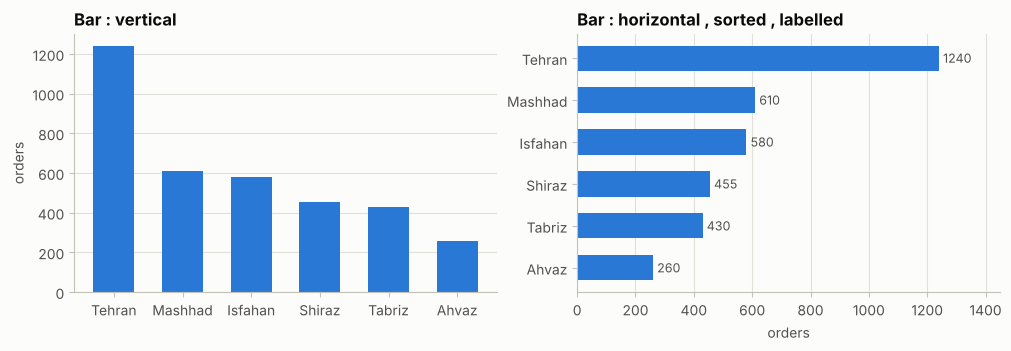

In [5]:
city_sales = pd.Series({"Tehran": 1240, "Mashhad": 610, "Isfahan": 580, "Shiraz": 455, "Tabriz": 430, "Ahvaz": 260})

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
ax = axes[0]
ax.bar(city_sales.index, city_sales.values, color=SERIES[0], width=0.6)
ax.set(title="Bar : vertical", ylabel="orders")
ax.grid(axis="x", visible=False)

ax = axes[1]
s = city_sales.sort_values()
bars = ax.barh(s.index, s.values, color=SERIES[0], height=0.6)
ax.bar_label(bars, padding=3, color=INK2, fontsize=9)
ax.set(title="Bar : horizontal , sorted , labelled", xlabel="orders")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, 1450)
plt.show()

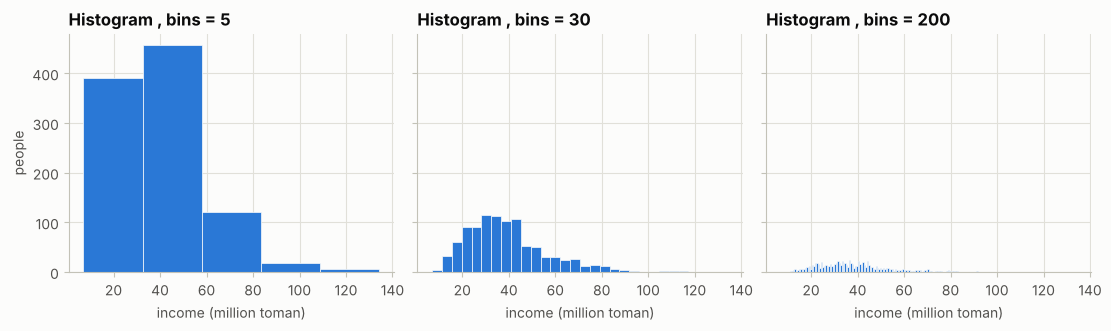

In [6]:
income = np.r_[rng.lognormal(10.5, 0.45, 995), [400_000, 520_000, 610_000, 700_000, 850_000]] / 1000

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for ax, bins in zip(axes, [5, 30, 200]):
    ax.hist(income[income < 150], bins=bins, color=SERIES[0], edgecolor=SURFACE, linewidth=0.5)
    ax.set(title=f"Histogram , bins = {bins}", xlabel="income (million toman)")
axes[0].set_ylabel("people")
plt.show()

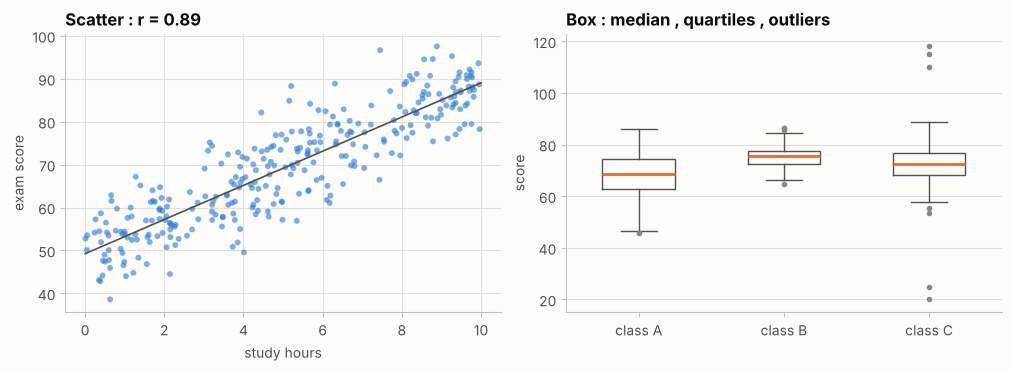

In [7]:
hours = rng.uniform(0, 10, 300)
score = 50 + 4 * hours + rng.normal(0, 6, 300)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
ax = axes[0]
ax.scatter(hours, score, s=18, alpha=0.6, color=SERIES[0], edgecolor="none")
slope, intercept = np.polyfit(hours, score, 1)
ax.plot([0, 10], [intercept, intercept + 10 * slope], color=INK2, linewidth=1.2)
ax.set(title=f"Scatter : r = {np.corrcoef(hours, score)[0, 1]:.2f}", xlabel="study hours", ylabel="exam score")

ax = axes[1]
groups = [rng.normal(70, 8, 200), rng.normal(75, 4, 200), np.r_[rng.normal(72, 6, 195), [20, 25, 110, 115, 118]]]
ax.boxplot(groups, tick_labels=["class A", "class B", "class C"], widths=0.5,
           medianprops={"color": SERIES[1], "linewidth": 2},
           boxprops={"color": INK2}, whiskerprops={"color": INK2}, capprops={"color": INK2},
           flierprops={"marker": "o", "markersize": 4, "markerfacecolor": MUTED, "markeredgecolor": "none"})
ax.set(title="Box : median , quartiles , outliers", ylabel="score")
ax.grid(axis="x", visible=False)
plt.show()

## 4. Layout : subplots and small multiples
    many series on one chart become spaghetti ; one small chart per series , with SHARED axes , stays readable

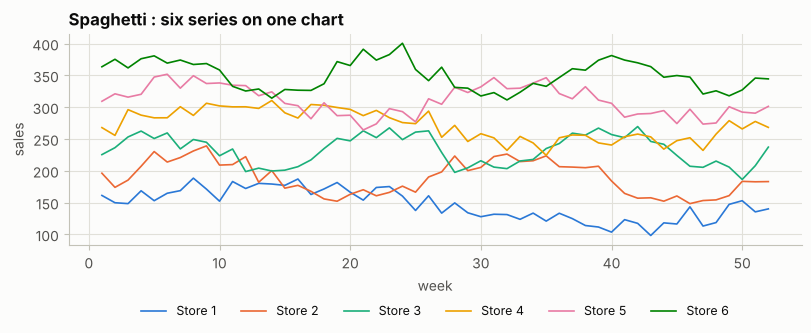

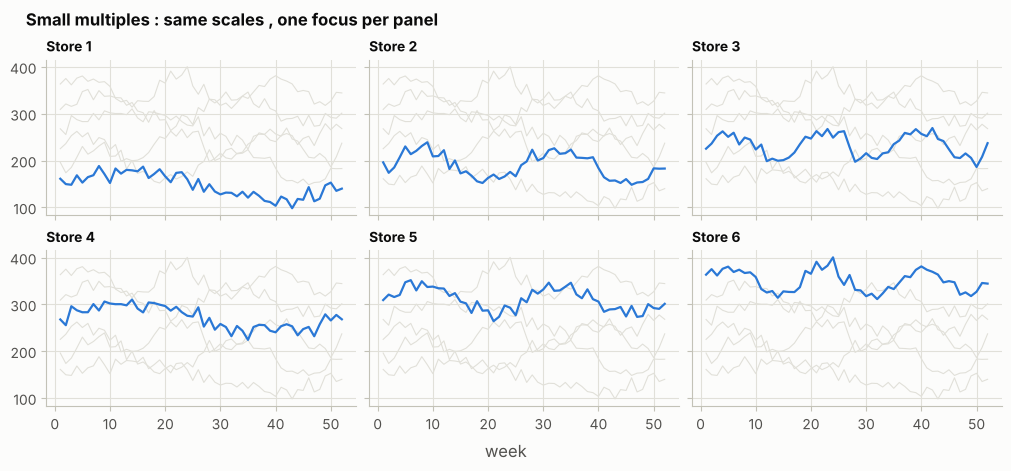

In [8]:
stores = {f"Store {i + 1}": 150 + 40 * i + 30 * np.sin(np.arange(52) / 52 * 2 * np.pi * (i % 3 + 1))
                             + rng.normal(0, 10, 52) for i in range(6)}
weeks = np.arange(1, 53)

fig, ax = plt.subplots(figsize=(8, 3.2))
for name, v in stores.items():
    ax.plot(weeks, v, linewidth=1.2, label=name)
ax.set(title="Spaghetti : six series on one chart", xlabel="week", ylabel="sales")
ax.legend(ncols=6, loc="upper center", bbox_to_anchor=(0.5, -0.22))
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(10, 4.6), sharex=True, sharey=True)
for ax, (name, v) in zip(axes.flat, stores.items()):
    for other in stores.values():
        ax.plot(weeks, other, color=GRID, linewidth=0.8)          # context in gray
    ax.plot(weeks, v, color=SERIES[0], linewidth=1.6)              # the focus
    ax.set_title(name, fontsize=10)
fig.suptitle("Small multiples : same scales , one focus per panel", x=0.02, ha="left", fontweight="bold")
fig.supxlabel("week", color=INK2)
plt.show()

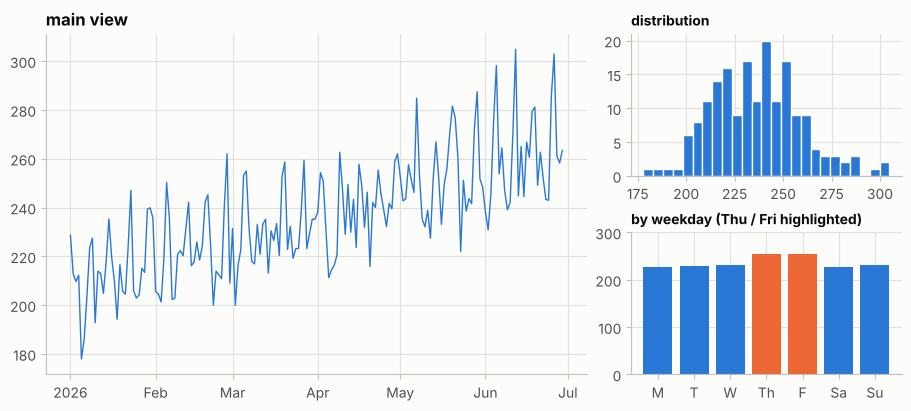

In [9]:
fig = plt.figure(figsize=(9, 4))
grid = fig.add_gridspec(2, 3)
big = fig.add_subplot(grid[:, :2])                 # spans 2 rows , 2 columns
top = fig.add_subplot(grid[0, 2])
bottom = fig.add_subplot(grid[1, 2])

big.plot(days, sales, linewidth=1, color=SERIES[0])
big.set_title("main view")
top.hist(sales, bins=25, color=SERIES[0], edgecolor=SURFACE)
top.set_title("distribution", fontsize=10)
weekday_mean = pd.Series(sales, index=days).groupby(days.dayofweek).mean()
bottom.bar(["M", "T", "W", "Th", "F", "Sa", "Su"], weekday_mean, color=[SERIES[1] if d in (3, 4) else SERIES[0] for d in range(7)])
bottom.set_title("by weekday (Thu / Fri highlighted)", fontsize=10)
bottom.set_ylim(0, 300)
plt.show()

## 5. Telling the story : annotations , reference lines , tick formats , log scale

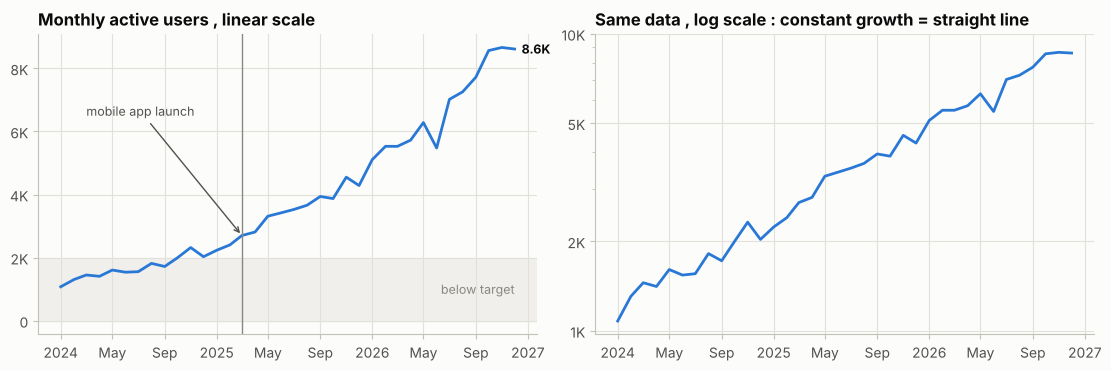

In [10]:
from matplotlib.ticker import FuncFormatter

users = pd.Series(1200 * 1.06 ** np.arange(36) * rng.lognormal(0, 0.06, 36),
                  index=pd.date_range("2024-01-01", periods=36, freq="MS"))
launch = pd.Timestamp("2025-03-01")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
ax.plot(users.index, users.values, color=SERIES[0])
ax.axvline(launch, color=MUTED, linewidth=1)
ax.annotate("mobile app launch", xy=(launch, users[launch]), xytext=(pd.Timestamp("2024-03-01"), 6500),
            arrowprops={"arrowstyle": "->", "color": INK2}, color=INK2, fontsize=9)
ax.axhspan(0, 2000, color=NEUTRAL, zorder=0)
ax.text(users.index[-1], 1000, "below target", ha="right", va="center", color=MUTED, fontsize=9)
last = users.iloc[-1]
ax.annotate(f"{last / 1000:.1f}K", xy=(users.index[-1], last), xytext=(5, 0), textcoords="offset points",
            va="center", color=INK, fontsize=9, fontweight="bold")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1000:.0f}K" if v else "0"))
ax.set(title="Monthly active users , linear scale")

ax = axes[1]
ax.plot(users.index, users.values, color=SERIES[0])
ax.set_yscale("log")
ax.set_yticks([1000, 2000, 5000, 10000])
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1000:g}K"))
ax.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: ""))
ax.set(title="Same data , log scale : constant growth = straight line")
plt.show()

## 6. Honest charts
    (a) never two y-scales on one chart : the alignment is arbitrary and invents correlations
    (b) bars encode length : the axis MUST start at zero

signups grew 92% , revenue grew 20%


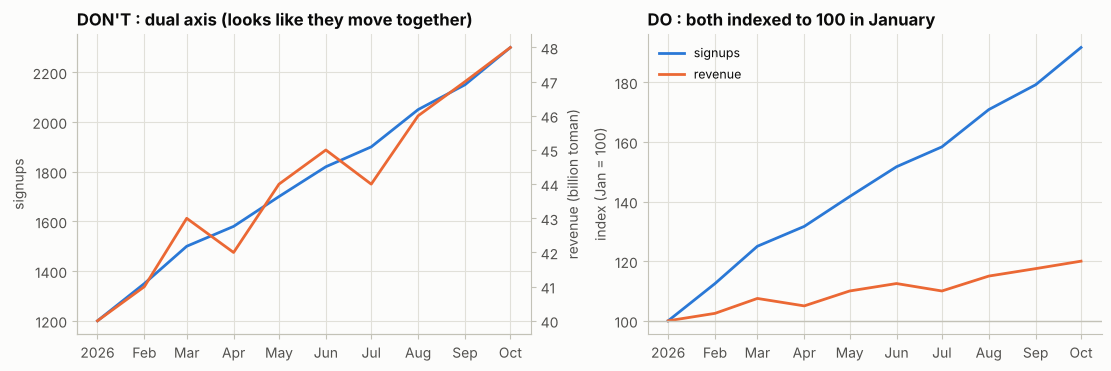

In [11]:
months = pd.date_range("2026-01-01", periods=10, freq="MS")
signups = np.array([1200, 1350, 1500, 1580, 1700, 1820, 1900, 2050, 2150, 2300])
revenue = np.array([40, 41, 43, 42, 44, 45, 44, 46, 47, 48.0])          # billion toman

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
ax.plot(months, signups, color=SERIES[0], label="signups")
ax2 = ax.twinx()                                                   # the anti-pattern
ax2.plot(months, revenue, color=SERIES[1], label="revenue")
ax2.spines["right"].set_visible(True)
ax2.grid(False)
ax.set_title("DON'T : dual axis (looks like they move together)")
ax.set_ylabel("signups")
ax2.set_ylabel("revenue (billion toman)")

ax = axes[1]
ax.plot(months, 100 * signups / signups[0], label="signups")
ax.plot(months, 100 * revenue / revenue[0], label="revenue")
ax.axhline(100, color=AXIS, linewidth=1)
ax.set(title="DO : both indexed to 100 in January", ylabel="index (Jan = 100)")
ax.legend(loc="upper left")
plt.show()
print(f"signups grew {signups[-1] / signups[0] - 1:.0%} , revenue grew {revenue[-1] / revenue[0] - 1:.0%}")

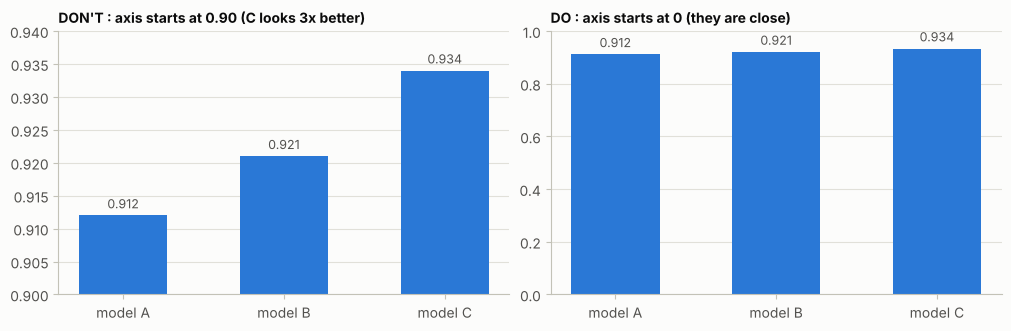

In [12]:
acc = pd.Series({"model A": 0.912, "model B": 0.921, "model C": 0.934})

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, ylim, title in [(axes[0], (0.90, 0.94), "DON'T : axis starts at 0.90 (C looks 3x better)"),
                        (axes[1], (0, 1), "DO : axis starts at 0 (they are close)")]:
    bars = ax.bar(acc.index, acc.values, color=SERIES[0], width=0.55)
    ax.bar_label(bars, fmt="%.3f", padding=3, color=INK2, fontsize=9)
    ax.set_ylim(*ylim)
    ax.set_title(title, fontsize=10)
    ax.grid(axis="x", visible=False)
plt.show()

## 7. Colour must do a JOB
    categorical ---> WHICH one ? (distinct hues , fixed order , at most 8 ; for scatter at most 3)
    sequential  ---> HOW MUCH ? (one hue , light -> dark)
    diverging   ---> ABOVE or BELOW a midpoint ? (two hues , neutral gray at the center)

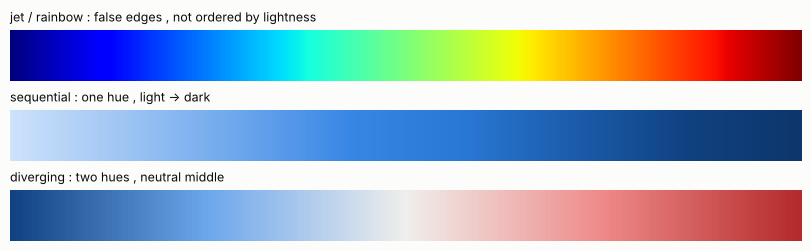

In [13]:
from matplotlib.colors import LinearSegmentedColormap

seq = LinearSegmentedColormap.from_list("blue_seq", BLUE_RAMP)
div = LinearSegmentedColormap.from_list("blue_red", ["#104281", "#6da7ec", NEUTRAL, "#ee8a89", "#b42b2a"])

gradient = np.linspace(0, 1, 256)[None, :]
fig, axes = plt.subplots(3, 1, figsize=(8, 2.4))
for ax, cmap, name in [(axes[0], "jet", "jet / rainbow : false edges , not ordered by lightness"),
                       (axes[1], seq, "sequential : one hue , light -> dark"),
                       (axes[2], div, "diverging : two hues , neutral middle")]:
    ax.imshow(gradient, aspect="auto", cmap=cmap)
    ax.set_axis_off()
    ax.set_title(name, fontsize=9, fontweight="normal")
plt.show()

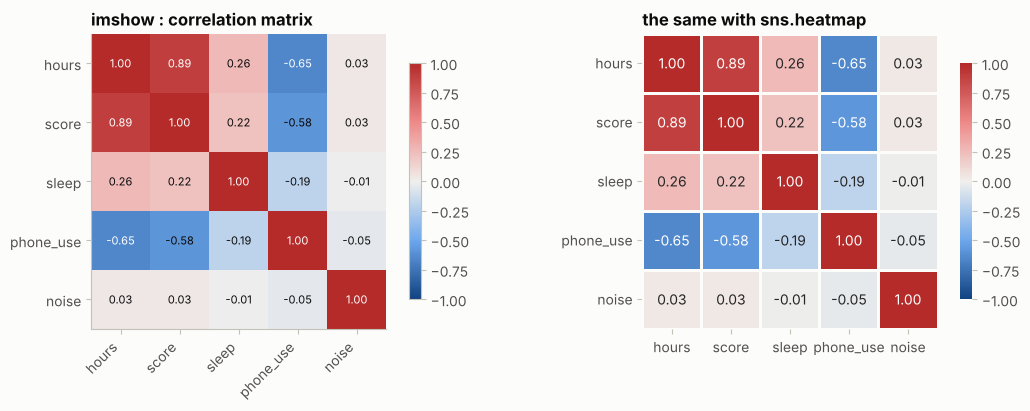

In [14]:
features = pd.DataFrame({
    "hours": hours,
    "score": score,
    "sleep": 7 + 0.1 * hours + rng.normal(0, 1, 300),
    "phone_use": 5 - 0.3 * hours + rng.normal(0, 1, 300),
    "noise": rng.normal(size=300),
})
corr = features.corr()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
im = ax.imshow(corr, cmap=div, vmin=-1, vmax=1)                   # centre MUST be 0
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(v) > 0.6 else INK)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("imshow : correlation matrix")

ax = axes[1]
sns.heatmap(corr, cmap=div, vmin=-1, vmax=1, annot=True, fmt=".2f", square=True,
            linewidths=2, linecolor=SURFACE, cbar_kws={"shrink": 0.8}, ax=ax)
ax.tick_params(axis="y", rotation=0)
ax.set_title("the same with sns.heatmap")
plt.show()

## 8. Seaborn : statistical plots straight from a (long) DataFrame
    data=df , x="column" , y="column" , hue="column" , col="column"
    the same churn dataset as the pandas session

In [15]:
rng = np.random.default_rng(42)
n = 2000
plan = rng.choice(["basic", "pro", "premium"], n, p=[0.6, 0.3, 0.1])
tenure = rng.integers(1, 61, n)
calls = rng.poisson(np.where(plan == "basic", 2.0, 1.0))
base_price = pd.Series(plan).map({"basic": 200, "pro": 450, "premium": 900}).to_numpy()
logit = -1.0 + 0.45 * calls - 0.05 * tenure + 0.5 * (plan == "basic")
customers = pd.DataFrame({
    "city": rng.choice(["Tehran", "Isfahan", "Shiraz", "Tabriz", "Mashhad"], n, p=[0.4, 0.15, 0.15, 0.15, 0.15]),
    "age": rng.integers(18, 70, n),
    "plan": pd.Categorical(plan, categories=["basic", "pro", "premium"], ordered=True),
    "tenure_months": tenure,
    "monthly_spend": (base_price * rng.lognormal(0, 0.25, n)).round(0),
    "support_calls": calls,
    "churned": np.where(rng.random(n) < 1 / (1 + np.exp(-logit)), "yes", "no"),
})
print(customers.head(3))
print(customers["churned"].value_counts(normalize=True).round(3).to_dict())

      city  age   plan  tenure_months  monthly_spend  support_calls churned
0   Tehran   27    pro             20          425.0              2     yes
1  Mashhad   25  basic             51          176.0              1      no
2   Tehran   46    pro              3          548.0              2      no
{'no': 0.79, 'yes': 0.21}


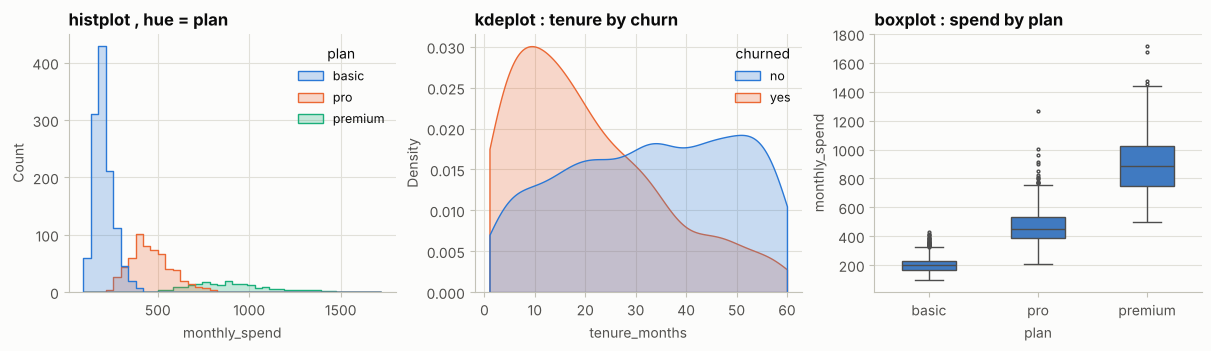

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
sns.histplot(customers, x="monthly_spend", hue="plan", bins=40, element="step", ax=axes[0])
axes[0].set_title("histplot , hue = plan")

sns.kdeplot(customers, x="tenure_months", hue="churned", common_norm=False, fill=True, alpha=0.25, clip=(1, 60),
            hue_order=["no", "yes"], ax=axes[1])
axes[1].set_title("kdeplot : tenure by churn")

sns.boxplot(customers, x="plan", y="monthly_spend", color=SERIES[0], width=0.5, fliersize=2,
            linewidth=1, ax=axes[2])
axes[2].set_title("boxplot : spend by plan")
plt.show()

support_calls       0       1       2       3       4      5      6    7
size           452.00  680.00  456.00  239.00  112.00  36.00  20.00  5.0
mean             0.09    0.18    0.25    0.25    0.39   0.64   0.55  0.4


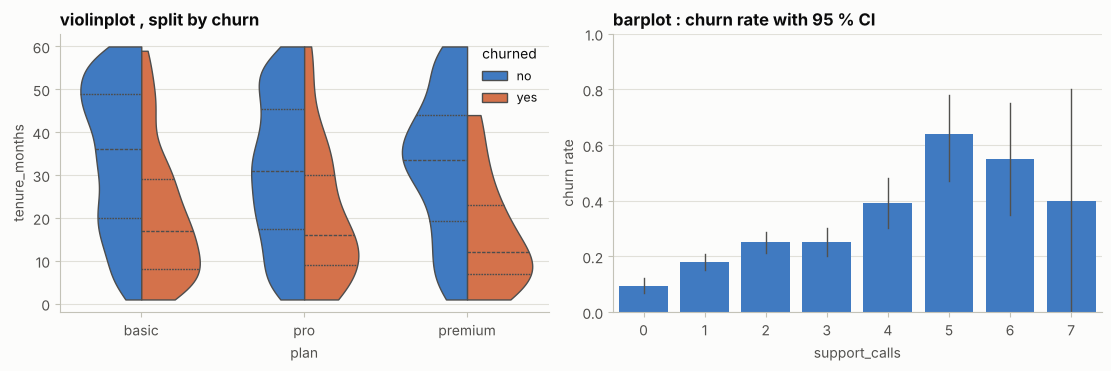

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
sns.violinplot(customers, x="plan", y="tenure_months", hue="churned", split=True, inner="quart", cut=0,
               hue_order=["no", "yes"], linewidth=1, ax=axes[0])
axes[0].set_title("violinplot , split by churn")

customers["churn_flag"] = (customers["churned"] == "yes").astype(int)
sns.barplot(customers, x="support_calls", y="churn_flag", color=SERIES[0],
            errorbar=("ci", 95), err_kws={"color": INK2, "linewidth": 1}, ax=axes[1])
axes[1].set(title="barplot : churn rate with 95 % CI", ylabel="churn rate", ylim=(0, 1))
axes[1].grid(axis="x", visible=False)
plt.show()
print(customers.groupby("support_calls")["churn_flag"].agg(["size", "mean"]).round(2).T)

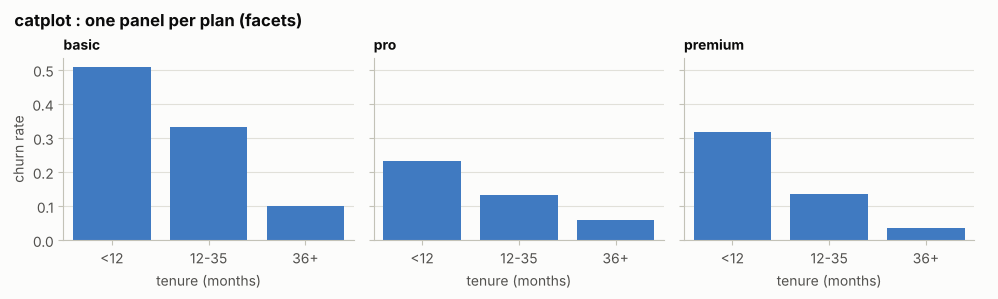

In [18]:
long = (customers.assign(tenure_group=pd.cut(customers["tenure_months"], [0, 12, 36, 61],
                                             labels=["<12", "12-35", "36+"], right=False))
                 .groupby(["plan", "tenure_group"], observed=True)["churn_flag"].mean()
                 .reset_index())
with plt.rc_context({"figure.constrained_layout.use": False}):     # seaborn grids manage their own layout
    g = sns.catplot(long, x="tenure_group", y="churn_flag", col="plan", kind="bar", color=SERIES[0],
                    height=3, aspect=1.1)
    g.set_axis_labels("tenure (months)", "churn rate")
    g.set_titles("{col_name}")
    g.figure.suptitle("catplot : one panel per plan (facets)", x=0.02, ha="left", fontweight="bold")
    g.figure.subplots_adjust(top=0.82)
plt.show()

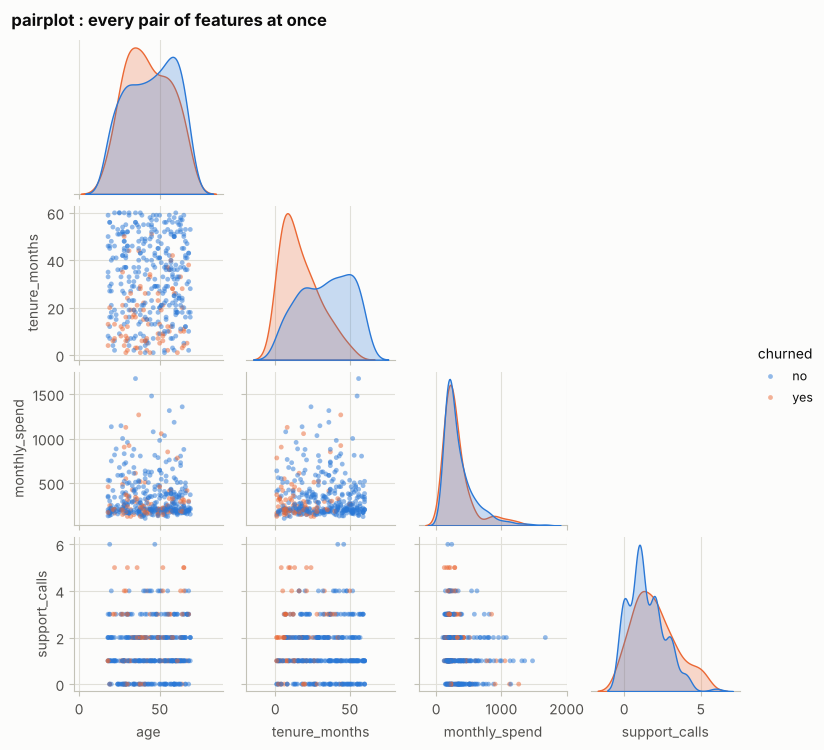

In [19]:
sample = customers.sample(400, random_state=0)
with plt.rc_context({"figure.constrained_layout.use": False}):
    g = sns.pairplot(sample, vars=["age", "tenure_months", "monthly_spend", "support_calls"], hue="churned",
                     hue_order=["no", "yes"], corner=True, height=1.9,
                     plot_kws={"s": 12, "alpha": 0.5, "edgecolor": "none"}, diag_kws={"common_norm": False})
    g.figure.suptitle("pairplot : every pair of features at once", x=0.02, ha="left", fontweight="bold")
    g.figure.subplots_adjust(top=0.94)
plt.show()

## 9. Saving figures

In [20]:
from pathlib import Path
out = Path("viz_demo")
out.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(days, sales, linewidth=1)
ax.set_title("Sales")
fig.savefig(out / "sales.png", dpi=200, bbox_inches="tight")     # raster : slides , chat , web
fig.savefig(out / "sales.svg", bbox_inches="tight")              # vector : papers , sharp at any zoom
fig.savefig(out / "sales.pdf", bbox_inches="tight")              # vector : LaTeX reports
plt.close(fig)                                                   # free memory when making many charts
for f in sorted(out.iterdir()):
    print(f"{f.name:10s} {f.stat().st_size / 1024:6.1f} KB")

CLEANUP = True
if CLEANUP:
    for f in out.iterdir():
        f.unlink()
    out.rmdir()

sales.pdf    12.7 KB
sales.png    97.5 KB
sales.svg    27.2 KB


## 10. Persian (right-to-left) labels
    recent Matplotlib shapes Persian correctly ; older versions show separated , reversed letters .
    fix for older versions :  pip install arabic-reshaper python-bidi

native right-to-left support: True


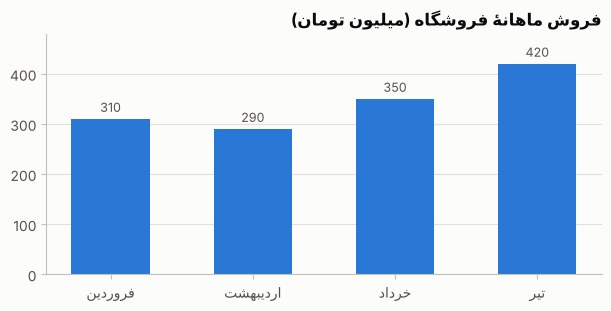

In [21]:
MPL_NATIVE_RTL = tuple(int(p) for p in matplotlib.__version__.split(".")[:2]) >= (3, 11)

def fa(text):
    if MPL_NATIVE_RTL:
        return text
    try:
        import arabic_reshaper
        from bidi.algorithm import get_display
        return get_display(arabic_reshaper.reshape(text))
    except ImportError:
        return text + "  (install arabic-reshaper + python-bidi)"

monthly = pd.Series([310, 290, 350, 420], index=["فروردین", "اردیبهشت", "خرداد", "تیر"])
fig, ax = plt.subplots(figsize=(6, 3))
bars = ax.bar([fa(m) for m in monthly.index], monthly.values, color=SERIES[0], width=0.55)
ax.bar_label(bars, padding=3, color=INK2, fontsize=9)
ax.set_title(fa("فروش ماهانهٔ فروشگاه (میلیون تومان)"), loc="right")
ax.set_ylim(0, 480)
ax.grid(axis="x", visible=False)
plt.show()
print("native right-to-left support:", MPL_NATIVE_RTL)

## 11. Applications in machine learning

best degree: 3 | val RMSE: 0.189 | degree 12 val RMSE: 6.073


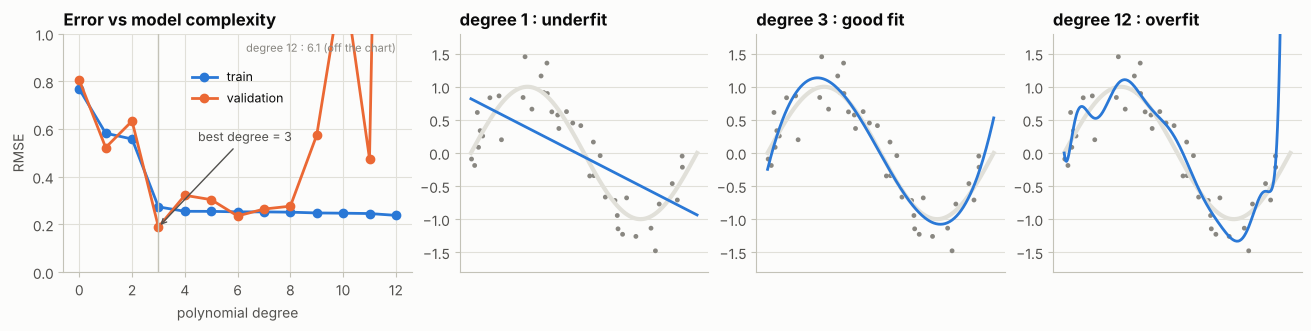

In [22]:
# Application 1 : bias-variance , polynomial degree vs error
rng = np.random.default_rng(0)
x_all = np.sort(rng.uniform(0, 1, 60))
y_all = np.sin(2 * np.pi * x_all) + rng.normal(0, 0.25, 60)
is_val = np.zeros(60, bool)
is_val[rng.choice(60, 20, replace=False)] = True
xt, yt, xv, yv = x_all[~is_val], y_all[~is_val], x_all[is_val], y_all[is_val]

degrees = range(0, 13)
train_err, val_err = [], []
for d in degrees:
    c = np.polyfit(xt, yt, d)
    train_err.append(np.sqrt(np.mean((np.polyval(c, xt) - yt) ** 2)))
    val_err.append(np.sqrt(np.mean((np.polyval(c, xv) - yv) ** 2)))
best = int(np.argmin(val_err))

fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), gridspec_kw={"width_ratios": [1.4, 1, 1, 1]})
ax = axes[0]
ax.plot(degrees, train_err, marker="o", label="train")
ax.plot(degrees, val_err, marker="o", label="validation")
ax.axvline(best, color=AXIS, linewidth=1)
ax.annotate(f"best degree = {best}", xy=(best, val_err[best]), xytext=(4.5, 0.55), color=INK2, fontsize=9,
            arrowprops={"arrowstyle": "->", "color": INK2})
ax.text(12, 0.97, f"degree 12 : {val_err[12]:.1f} (off the chart)", ha="right", va="top", color=MUTED, fontsize=8)
ax.set(title="Error vs model complexity", xlabel="polynomial degree", ylabel="RMSE", ylim=(0, 1.0))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0.9))

grid_x = np.linspace(0, 1, 300)
for ax, d, label in zip(axes[1:], [1, best, 12], ["underfit", "good fit", "overfit"]):
    ax.scatter(xt, yt, s=12, color=MUTED, edgecolor="none")
    ax.plot(grid_x, np.sin(2 * np.pi * grid_x), color=GRID, linewidth=3)
    ax.plot(grid_x, np.polyval(np.polyfit(xt, yt, d), grid_x), color=SERIES[0])
    ax.set(title=f"degree {d} : {label}", ylim=(-1.8, 1.8))
    ax.set_xticks([])
plt.show()
print("best degree:", best, "| val RMSE:", round(val_err[best], 3), "| degree 12 val RMSE:", round(val_err[12], 3))

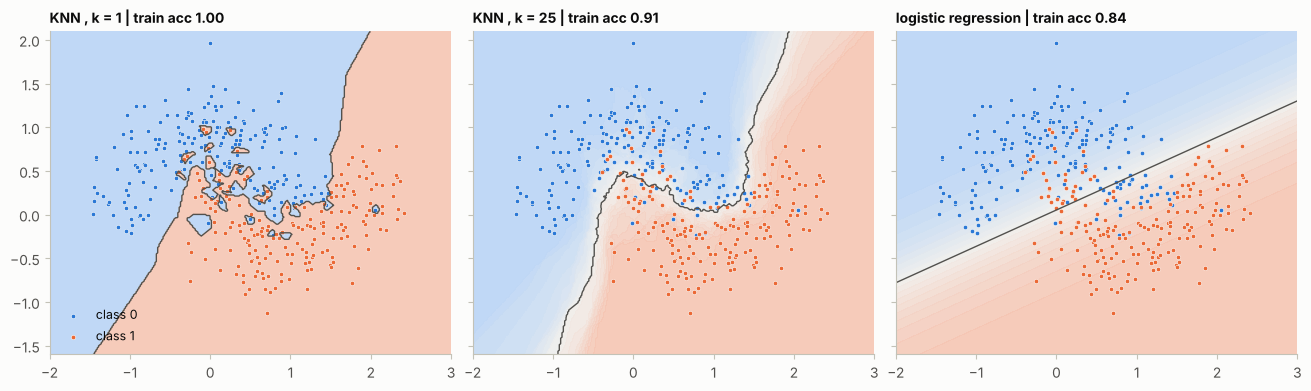

In [23]:
# Application 2 : decision boundaries on a meshgrid (KNN k=1 vs k=25 , logistic regression)
from sklearn.datasets import make_moons
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

Xm, ym = make_moons(400, noise=0.3, random_state=1)
xx, yy = np.meshgrid(np.linspace(-2, 3, 300), np.linspace(-1.6, 2.1, 300))
grid_pts = np.c_[xx.ravel(), yy.ravel()]
two = LinearSegmentedColormap.from_list("two", ["#b7d3f6", NEUTRAL, "#f6c4b0"])

models = [("KNN , k = 1", KNeighborsClassifier(1)), ("KNN , k = 25", KNeighborsClassifier(25)),
          ("logistic regression", LogisticRegression())]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True, sharey=True)
for ax, (name, m) in zip(axes, models):
    m.fit(Xm, ym)
    proba = m.predict_proba(grid_pts)[:, 1].reshape(xx.shape)
    ax.contourf(xx, yy, proba, levels=20, cmap=two, alpha=0.9)
    ax.contour(xx, yy, proba, levels=[0.5], colors=INK2, linewidths=1)
    for cls, color in [(0, SERIES[0]), (1, SERIES[1])]:
        ax.scatter(*Xm[ym == cls].T, s=10, color=color, edgecolor=SURFACE, linewidth=0.4, label=f"class {cls}")
    ax.set_title(f"{name} | train acc {m.score(Xm, ym):.2f}", fontsize=10)
    ax.grid(False)
axes[0].legend(loc="lower left")
plt.show()

AUC 0.794 | average precision 0.605 | churn rate 0.210


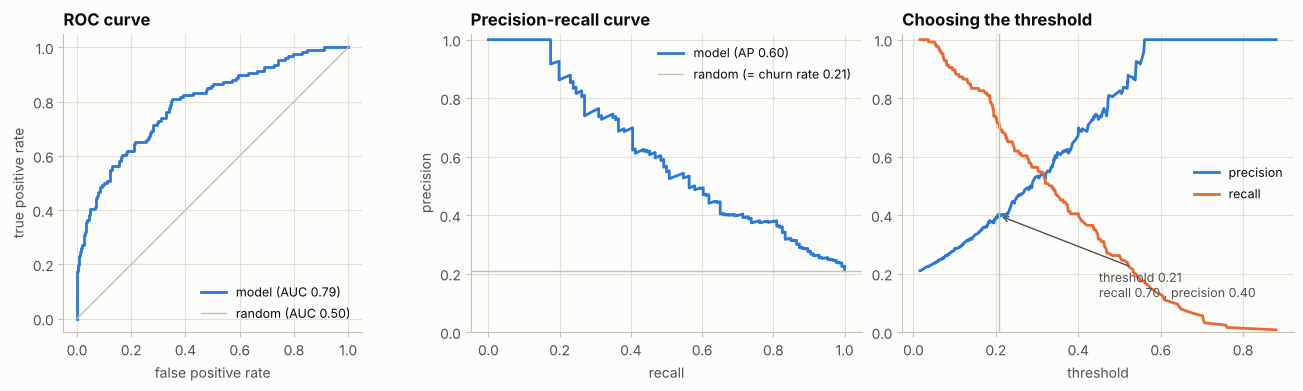

In [24]:
# Application 3 : evaluating a churn classifier : ROC , precision-recall , threshold choice
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, average_precision_score

X = pd.get_dummies(customers[["age", "tenure_months", "monthly_spend", "support_calls", "plan"]],
                   columns=["plan"], dtype=float)
y = customers["churn_flag"].to_numpy()
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
X_tr = X_tr.astype(float)
mu, sd = X_tr.mean(), X_tr.std()
clf = LogisticRegression(max_iter=1000).fit((X_tr - mu) / sd, y_tr)
p = clf.predict_proba((X_te - mu) / sd)[:, 1]

fpr, tpr, _ = roc_curve(y_te, p)
prec, rec, thr = precision_recall_curve(y_te, p)
auc, ap, base = roc_auc_score(y_te, p), average_precision_score(y_te, p), y_te.mean()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
ax = axes[0]
ax.plot(fpr, tpr, label=f"model (AUC {auc:.2f})")
ax.plot([0, 1], [0, 1], color=AXIS, linewidth=1, label="random (AUC 0.50)")
ax.set(title="ROC curve", xlabel="false positive rate", ylabel="true positive rate", aspect="equal")
ax.legend(loc="lower right")

ax = axes[1]
ax.plot(rec, prec, label=f"model (AP {ap:.2f})")
ax.axhline(base, color=AXIS, linewidth=1, label=f"random (= churn rate {base:.2f})")
ax.set(title="Precision-recall curve", xlabel="recall", ylabel="precision", ylim=(0, 1.02))
ax.legend(loc="upper right")

ax = axes[2]
ax.plot(thr, prec[:-1], label="precision")
ax.plot(thr, rec[:-1], label="recall")
i = np.argmin(np.abs(rec[:-1] - 0.7))
ax.axvline(thr[i], color=AXIS, linewidth=1)
ax.annotate(f"threshold {thr[i]:.2f}\nrecall 0.70 , precision {prec[i]:.2f}", xy=(thr[i], prec[i]),
            xytext=(0.45, 0.12), color=INK2, fontsize=9, arrowprops={"arrowstyle": "->", "color": INK2})
ax.set(title="Choosing the threshold", xlabel="threshold", ylim=(0, 1.02))
ax.legend(loc="center right")
plt.show()
print(f"AUC {auc:.3f} | average precision {ap:.3f} | churn rate {base:.3f}")

[[341 133]
 [ 38  88]]


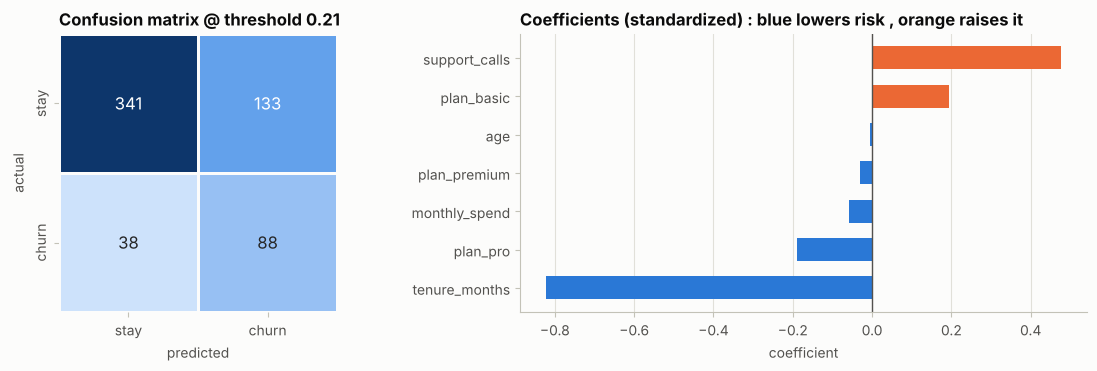

In [25]:
# Application 4 : confusion matrix and coefficients
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_te, p >= thr[i])
coef = pd.Series(clf.coef_[0], index=X.columns).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 1.4]})
ax = axes[0]
sns.heatmap(cm, annot=True, fmt="d", cmap=seq, cbar=False, square=True, linewidths=2, linecolor=SURFACE,
            xticklabels=["stay", "churn"], yticklabels=["stay", "churn"], annot_kws={"size": 12}, ax=ax)
ax.set(title=f"Confusion matrix @ threshold {thr[i]:.2f}", xlabel="predicted", ylabel="actual")

ax = axes[1]
colors = [SERIES[0] if v < 0 else SERIES[1] for v in coef]
ax.barh(coef.index, coef.values, color=colors, height=0.6)
ax.axvline(0, color=INK2, linewidth=1)
ax.set(title="Coefficients (standardized) : blue lowers risk , orange raises it", xlabel="coefficient")
ax.grid(axis="y", visible=False)
plt.show()
print(cm)

alarms: 4 | injected: 4 | caught: 4


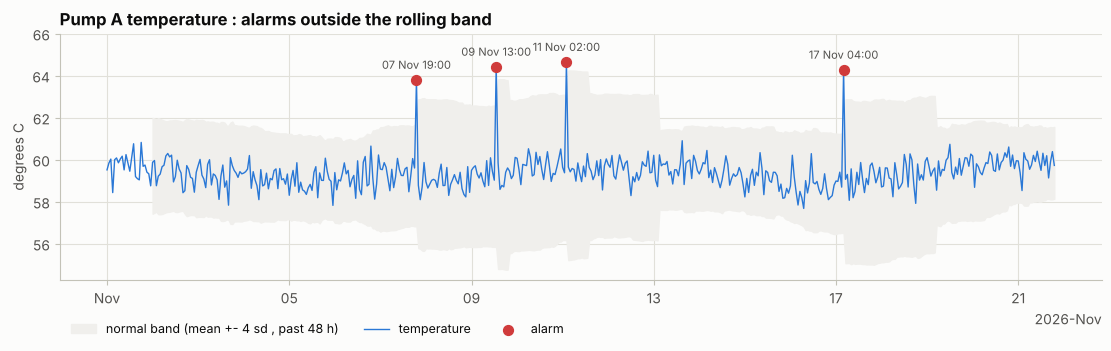

In [26]:
# Application 5 : sensor monitoring dashboard : rolling band + alarms
rng = np.random.default_rng(5)
t = pd.date_range("2026-11-01", periods=500, freq="h")
temp = pd.Series(60 + np.cumsum(rng.normal(0, 0.05, 500)) + rng.normal(0, 0.5, 500), index=t)
spikes = rng.choice(np.arange(60, 500), 4, replace=False)
temp.iloc[spikes] += 5

mu = temp.shift(1).rolling(48, min_periods=24).mean()
sd = temp.shift(1).rolling(48, min_periods=24).std()
alarm = (temp - mu).abs() > 4 * sd

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.fill_between(t, mu - 4 * sd, mu + 4 * sd, color=NEUTRAL, label="normal band (mean +- 4 sd , past 48 h)")
ax.plot(t, temp, linewidth=1, color=SERIES[0], label="temperature")
ax.scatter(t[alarm], temp[alarm], s=50, color="#d03b3b", zorder=3, label="alarm")
for ts, v in temp[alarm].items():
    ax.annotate(ts.strftime("%d %b %H:%M"), xy=(ts, v), xytext=(0, 8), textcoords="offset points",
                ha="center", fontsize=8, color=INK2)
ax.set(title="Pump A temperature : alarms outside the rolling band", ylabel="degrees C")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.12), ncols=3)
ax.set_ylim(top=66)
plt.show()
print("alarms:", int(alarm.sum()), "| injected:", len(spikes), "| caught:", int(alarm.iloc[spikes].sum()))

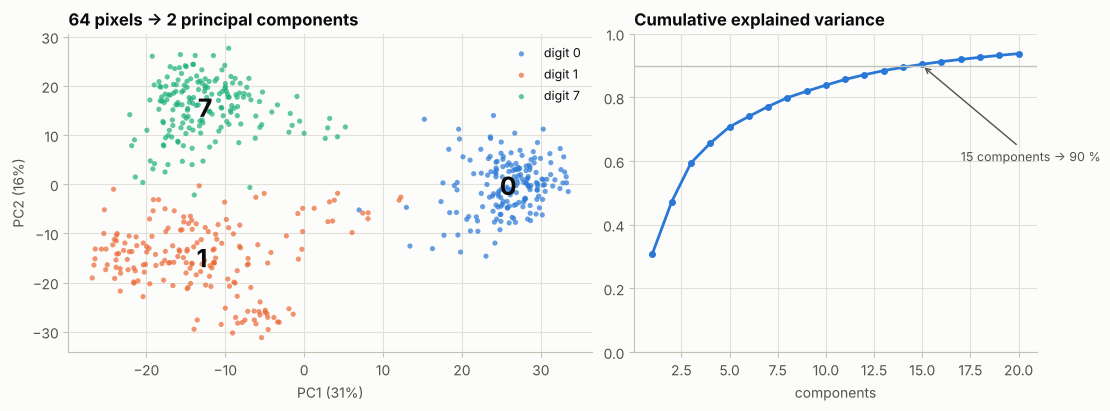

In [27]:
# Application 6 : PCA map of handwritten digits (3 classes : the safe limit for colours in a scatter)
from sklearn.datasets import load_digits

digits = load_digits()
keep = np.isin(digits.target, [0, 1, 7])
Xd, yd = digits.data[keep], digits.target[keep]
Xc = Xd - Xd.mean(axis=0)
U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
Z = Xc @ Vt[:2].T
explained = S ** 2 / (S ** 2).sum()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
for k, d in enumerate([0, 1, 7]):
    pts = Z[yd == d]
    ax.scatter(*pts.T, s=14, alpha=0.7, color=SERIES[k], edgecolor="none", label=f"digit {d}")
    cx, cy = pts.mean(axis=0)
    ax.text(cx, cy, str(d), fontsize=18, fontweight="bold", color=INK, ha="center", va="center")
ax.set(title="64 pixels -> 2 principal components", xlabel=f"PC1 ({explained[0]:.0%})", ylabel=f"PC2 ({explained[1]:.0%})")
ax.legend(loc="upper right")

ax = axes[1]
ax.plot(np.arange(1, 21), np.cumsum(explained)[:20], marker="o", markersize=4)
ax.axhline(0.9, color=AXIS, linewidth=1)
k90 = int(np.argmax(np.cumsum(explained) >= 0.9)) + 1
ax.annotate(f"{k90} components -> 90 %", xy=(k90, 0.9), xytext=(k90 + 2, 0.6), color=INK2, fontsize=9,
            arrowprops={"arrowstyle": "->", "color": INK2})
ax.set(title="Cumulative explained variance", xlabel="components", ylim=(0, 1))
plt.show()

eigenvalues of H: [ 0.338 23.662] | divergence above lr = 0.0845


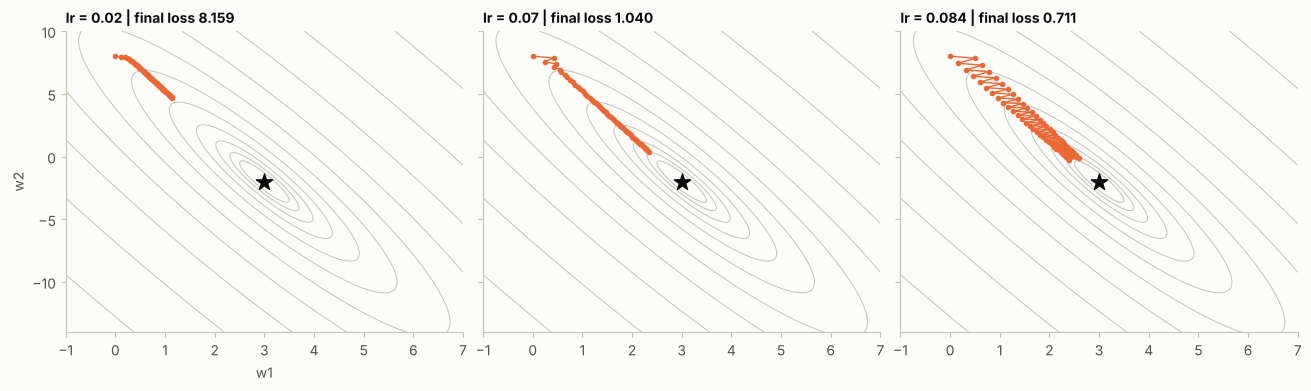

In [28]:
# Application 7 : gradient descent paths on a loss surface (same loss as the loops session)
H = np.array([[22.0, 6.0], [6.0, 2.0]])
w_star = np.array([3.0, -2.0])
loss = lambda W: 0.5 * np.einsum("...i,ij,...j->...", W - w_star, H, W - w_star)

W1, W2 = np.meshgrid(np.linspace(-1, 7, 300), np.linspace(-14, 10, 300))
L = loss(np.stack([W1, W2], axis=-1))

def gd(lr, steps=60):
    w = np.array([0.0, 8.0])
    path = [w.copy()]
    for _ in range(steps):
        w = w - lr * H @ (w - w_star)
        path.append(w.copy())
    return np.array(path)

print("eigenvalues of H:", np.linalg.eigvalsh(H).round(3), "| divergence above lr =", round(2 / np.linalg.eigvalsh(H).max(), 4))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True, sharey=True)
for ax, lr in zip(axes, [0.02, 0.07, 0.084]):
    P = gd(lr)
    ax.contour(W1, W2, L, levels=np.geomspace(0.5, 800, 12), colors=AXIS, linewidths=0.7)
    ax.plot(P[:, 0], P[:, 1], marker="o", markersize=3, linewidth=1, color=SERIES[1])
    ax.scatter(*w_star, marker="*", s=150, color=INK, zorder=3)
    ax.set_title(f"lr = {lr} | final loss {loss(P[-1]):.3f}", fontsize=10)
    ax.grid(False)
axes[0].set(xlabel="w1", ylabel="w2")
plt.show()

## Exercises
1. plot sigmoid and its derivative `s * (1 - s)` on one Axes ; mark the maximum of the derivative with `annotate`.
2. redraw the spaghetti chart of section 4 so that only Store 4 is coloured and the others are gray , with a direct label at its end.
3. make a histogram of `monthly_spend` with `np.log10` on the x values , and compare it with `ax.set_xscale("log")`.
4. find a pair in section 6 where a dual-axis chart would suggest a correlation that the indexed chart does not show.
5. draw the confusion matrix of Application 4 as RATES per actual class (`normalize="true"`).
6. in Application 2 , add an SVM with an RBF kernel (`sklearn.svm.SVC(probability=True)`) as a fourth panel.
7. in Application 3 , add the curve of a model that uses only `support_calls` : how much worse is it ?
8. in Application 6 , use digits 3 , 5 , 8 instead : are they separated as well ? why ?
9. in Application 7 , try lr = 0.086 : what happens and why ? (look at the printed eigenvalues)
10. rebuild one chart of this notebook in Persian with `fa()` and save it as a 200-dpi PNG.